Vocabulary size: 23
Dataset shape: (2000, 40)

Training without clipping
No Clipping | Epoch: 1 | Loss: 4.9863
No Clipping | Epoch: 2 | Loss: 5.2831
No Clipping | Epoch: 3 | Loss: 5.2811
No Clipping | Epoch: 4 | Loss: 5.2551
No Clipping | Epoch: 5 | Loss: 5.2602

Training with clipnorm = 1.0
Clipnorm 1.0 | Epoch: 1 | Loss: 2.9374
Clipnorm 1.0 | Epoch: 2 | Loss: 1.3722
Clipnorm 1.0 | Epoch: 3 | Loss: 0.4007
Clipnorm 1.0 | Epoch: 4 | Loss: 0.0785
Clipnorm 1.0 | Epoch: 5 | Loss: 0.0326

Training with clipvalue = 0.5
Clipvalue 0.5 | Epoch: 1 | Loss: 4.8949
Clipvalue 0.5 | Epoch: 2 | Loss: 4.685
Clipvalue 0.5 | Epoch: 3 | Loss: 3.877
Clipvalue 0.5 | Epoch: 4 | Loss: 3.2104
Clipvalue 0.5 | Epoch: 5 | Loss: 2.9032

GRADIENT CLIPPING COMPARISON
          Method  Final Loss  Maximum Gradient Norm
0    No Clipping      5.2602               113.8615
1   Clipnorm 1.0      0.0326                 8.7030
2  Clipvalue 0.5      2.9032               154.7514


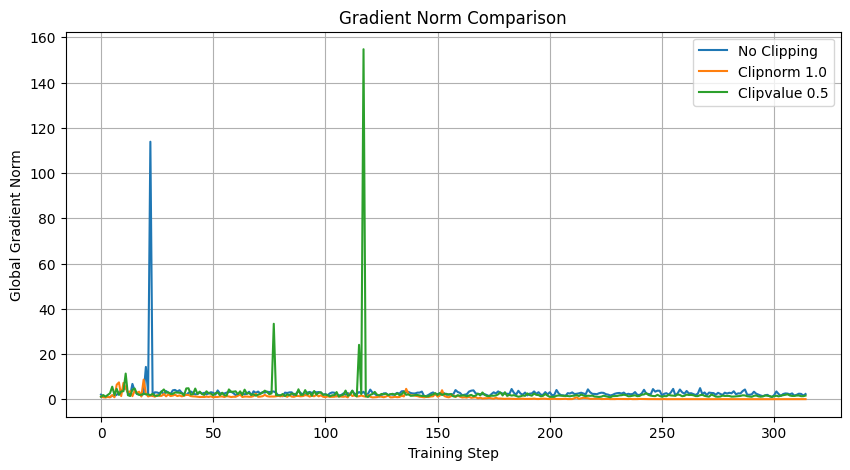

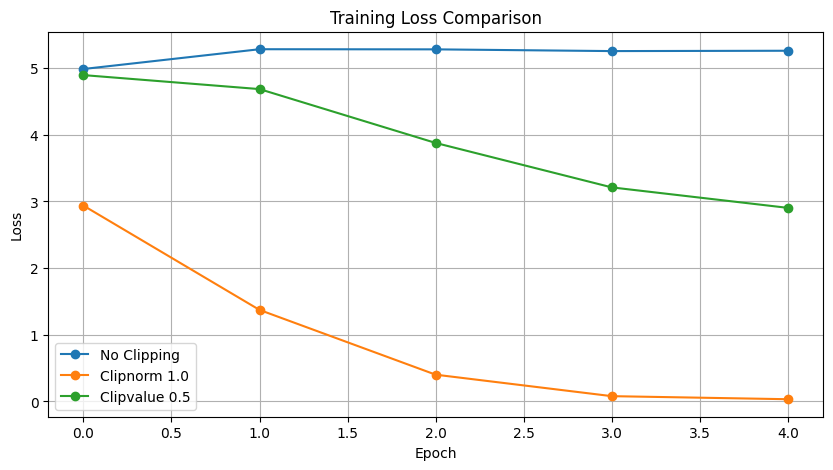


EXPERIMENT 17 COMPLETED!
Gradient clipping analysis performed.
Methods compared: No clipping, Clipnorm and Clipvalue.


In [21]:
# EXPERIMENT 17: RNN GRADIENT ANALYSIS AND GRADIENT CLIPPING

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd

from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

# 1. CREATE CHARACTER-LEVEL TEXT DATA

text_data = (
    "deep learning models learn patterns from data. "
    "recurrent neural networks process sequential information. "
    "gradient clipping helps training remain stable. "
) * 100

characters = sorted(set(text_data))
char_to_id = {c: i for i, c in enumerate(characters)}

encoded_text = np.array(
    [char_to_id[c] for c in text_data]
)

vocab_size = len(characters)

# Create input and target sequences

sequence_length = 40

X = []
y = []

for i in range(len(encoded_text) - sequence_length):
    X.append(encoded_text[i:i+sequence_length])
    y.append(encoded_text[i+sequence_length])

X = np.array(X)
y = np.array(y)

# Use a smaller dataset for quick execution

X = X[:2000]
y = y[:2000]

print("Vocabulary size:", vocab_size)
print("Dataset shape:", X.shape)

# 2. CREATE RNN MODEL

def create_model():

    model = tf.keras.Sequential([
        Embedding(vocab_size, 16),
        SimpleRNN(32),
        Dense(vocab_size)
    ])

    return model

# 3. CUSTOM TRAINING FUNCTION

def train_model(name, clipping=None, threshold=None):

    model = create_model()

    if clipping == "clipnorm":
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=1.0,
            clipnorm=threshold
        )

    elif clipping == "clipvalue":
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=1.0,
            clipvalue=threshold
        )

    else:
        optimizer = tf.keras.optimizers.SGD(
            learning_rate=1.0
        )

    loss_function = tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    )

    losses = []
    gradient_norms = []

    batch_size = 32
    epochs = 5

    for epoch in range(epochs):

        epoch_losses = []

        for start in range(0, len(X), batch_size):

            xb = X[start:start+batch_size]
            yb = y[start:start+batch_size]

            with tf.GradientTape() as tape:

                predictions = model(xb, training=True)

                loss = loss_function(yb, predictions)

            gradients = tape.gradient(
                loss,
                model.trainable_variables
            )

            # Calculate global gradient norm

            norm = tf.linalg.global_norm(gradients)

            norm_value = float(norm.numpy())

            gradient_norms.append(norm_value)

            # Stop if loss or gradients become unstable

            if (
                not np.isfinite(loss.numpy())
                or not np.isfinite(norm_value)
            ):

                print(name, "- unstable training detected!")

                return losses, gradient_norms

            optimizer.apply_gradients(
                zip(gradients, model.trainable_variables)
            )

            epoch_losses.append(float(loss.numpy()))

        avg_loss = np.mean(epoch_losses)

        losses.append(avg_loss)

        print(
            name,
            "| Epoch:", epoch + 1,
            "| Loss:", round(avg_loss, 4)
        )

    return losses, gradient_norms

# 4. TRAIN WITHOUT CLIPPING

print("\nTraining without clipping")

loss_none, grad_none = train_model(
    "No Clipping"
)

# 5. TRAIN WITH CLIPNORM

print("\nTraining with clipnorm = 1.0")

loss_norm, grad_norm = train_model(
    "Clipnorm 1.0",
    clipping="clipnorm",
    threshold=1.0
)

# 6. TRAIN WITH CLIPVALUE

print("\nTraining with clipvalue = 0.5")

loss_value, grad_value = train_model(
    "Clipvalue 0.5",
    clipping="clipvalue",
    threshold=0.5
)

# 7. CREATE SUMMARY TABLE

results = pd.DataFrame({
    "Method": [
        "No Clipping",
        "Clipnorm 1.0",
        "Clipvalue 0.5"
    ],
    "Final Loss": [
        loss_none[-1] if len(loss_none) else np.nan,
        loss_norm[-1] if len(loss_norm) else np.nan,
        loss_value[-1] if len(loss_value) else np.nan
    ],
    "Maximum Gradient Norm": [
        max(grad_none) if len(grad_none) else np.nan,
        max(grad_norm) if len(grad_norm) else np.nan,
        max(grad_value) if len(grad_value) else np.nan
    ]
})

print("\nGRADIENT CLIPPING COMPARISON")

print(results.round(4))

# 8. GRADIENT NORM GRAPH

plt.figure(figsize=(10, 5))

if len(grad_none):
    plt.plot(grad_none, label="No Clipping")

if len(grad_norm):
    plt.plot(grad_norm, label="Clipnorm 1.0")

if len(grad_value):
    plt.plot(grad_value, label="Clipvalue 0.5")

plt.title("Gradient Norm Comparison")
plt.xlabel("Training Step")
plt.ylabel("Global Gradient Norm")
plt.legend()
plt.grid(True)
plt.show()

# 9. LOSS GRAPH

plt.figure(figsize=(10, 5))

if len(loss_none):
    plt.plot(loss_none, marker="o", label="No Clipping")

if len(loss_norm):
    plt.plot(loss_norm, marker="o", label="Clipnorm 1.0")

if len(loss_value):
    plt.plot(loss_value, marker="o", label="Clipvalue 0.5")

plt.title("Training Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 10. FINAL OUTPUT

print("\nEXPERIMENT 17 COMPLETED!")
print("Gradient clipping analysis performed.")
print("Methods compared: No clipping, Clipnorm and Clipvalue.")